**Food Delivery Orders Analytics**

Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

1. Data Import

In [2]:
df=pd.read_csv('Datasets\\food_delivery_orders_dataset.csv')

In [3]:
# 1. Dataset dimensions
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (50000, 37)
Number of Rows: 50000
Number of Columns: 37


In [4]:
# 2. Column names
print("Column Names:")
print(df.columns.tolist())

Column Names:
['order_id', 'customer_id', 'restaurant_id', 'driver_id', 'order_timestamp', 'order_date', 'order_hour', 'day_of_week', 'is_weekend', 'city', 'delivery_area', 'customer_age', 'customer_type', 'restaurant_type', 'restaurant_primary_category', 'restaurant_rating', 'items_count', 'subtotal', 'discount_percent', 'tax_amount', 'service_fee', 'delivery_fee', 'order_total', 'payment_method', 'tip_amount', 'distance_km', 'weather', 'traffic_level', 'delivery_partner_experience_months', 'delivery_partner_rating', 'restaurant_preparation_time_minutes', 'estimated_delivery_time_minutes', 'actual_delivery_time_minutes', 'late_delivery', 'order_status', 'cancellation_reason', 'customer_rating']


In [5]:
# 3. Data types and non-null counts
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 37 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_id                             50000 non-null  object 
 1   customer_id                          50000 non-null  object 
 2   restaurant_id                        50000 non-null  object 
 3   driver_id                            50000 non-null  object 
 4   order_timestamp                      50000 non-null  object 
 5   order_date                           50000 non-null  object 
 6   order_hour                           50000 non-null  int64  
 7   day_of_week                          50000 non-null  object 
 8   is_weekend                           50000 non-null  int64  
 9   city                                 50000 non-null  object 
 10  delivery_area                        50000 non-null  object 
 11  custome

In [6]:
# 4. First 5 records
print("First 5 Records:")
display(df.head())

First 5 Records:


,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,05-10-2025 15:54,05-10-2025,15,Sunday,1,City_C,...,Medium,14,4.4,25,25,29.0,0.0,Completed,NaN,4.6
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,01-10-2025 20:00,01-10-2025,20,Wednesday,0,City_A,...,High,44,4.7,12,20,24.0,0.0,Completed,NaN,5.0
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,07-10-2025 18:24,07-10-2025,18,Tuesday,0,City_C,...,High,1,5.0,11,63,72.0,1.0,Completed,NaN,3.6
3,ORD_000004,CUS_00007,RES_0001,DRV_0177,30-10-2025 16:54,30-10-2025,16,Thursday,0,City_A,...,Low,50,4.3,12,23,31.0,1.0,Completed,NaN,4.1
4,ORD_000005,CUS_00325,RES_0029,DRV_0114,15-10-2025 18:34,15-10-2025,18,Wednesday,0,City_B,...,Medium,21,4.0,9,32,42.0,1.0,Completed,NaN,3.9


In [7]:
# 5. Random 5 records
print("Random 5 Records:")
display(df.sample(5, random_state=42))

Random 5 Records:


,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
33553,ORD_033554,CUS_00002,RES_0026,DRV_0195,16-10-2025 03:25,16-10-2025,3,Thursday,0,City_C,...,Low,15,4.7,12,15,16.0,0.0,Completed,NaN,4.7
9427,ORD_009428,CUS_00006,RES_0009,DRV_0033,02-10-2025 13:10,02-10-2025,13,Thursday,0,City_B,...,Low,28,4.3,18,31,33.0,0.0,Completed,NaN,5.0
199,ORD_000200,CUS_00186,RES_0036,DRV_0031,18-10-2025 14:27,18-10-2025,14,Saturday,1,City_C,...,Medium,25,5.0,10,38,40.0,0.0,Completed,NaN,4.6
12447,ORD_012448,CUS_00001,RES_0119,DRV_0064,07-10-2025 12:46,07-10-2025,12,Tuesday,0,City_C,...,Medium,29,4.3,10,19,26.0,1.0,Completed,NaN,3.6
39489,ORD_039490,CUS_00076,RES_0005,DRV_0192,04-10-2025 09:10,04-10-2025,9,Saturday,1,City_A,...,Medium,6,4.8,16,26,31.0,0.0,Completed,NaN,4.4


In [8]:
# 6. Numerical summary
print("Numerical Summary:")
display(df.describe().round(2))

Numerical Summary:


,order_hour,is_weekend,customer_age,restaurant_rating,items_count,subtotal,discount_percent,tax_amount,service_fee,delivery_fee,order_total,tip_amount,distance_km,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,customer_rating
count,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,49132.00,50000.00,50000.00,50000.00,50000.00,50000.00,49132.00,49132.00,49132.00
mean,14.47,0.27,27.69,4.21,2.91,30.90,4.50,4.13,1.47,3.08,38.17,1.61,4.73,29.73,4.50,15.55,30.95,35.15,0.37,4.30
std,5.23,0.44,7.54,0.45,2.03,27.07,6.43,3.64,1.38,2.30,31.05,2.88,2.78,17.41,0.35,7.36,12.83,14.70,0.48,0.53
min,0.00,0.00,18.00,2.80,1.00,5.10,0.00,0.57,0.13,0.00,4.87,0.00,0.80,1.00,3.20,5.00,8.00,10.00,0.00,1.80
25%,11.00,0.00,21.00,3.90,1.00,13.10,0.00,1.73,0.58,0.00,17.43,0.00,2.80,14.00,4.30,10.00,22.00,25.00,0.00,4.00
50%,14.00,0.00,27.00,4.20,2.00,22.82,0.00,2.89,1.04,3.50,28.35,0.00,4.10,29.00,4.50,14.00,28.00,33.00,0.00,4.40
75%,19.00,1.00,33.00,4.60,4.00,40.12,10.00,5.39,1.89,4.50,48.66,2.28,5.90,44.00,4.80,19.00,37.00,42.00,1.00,4.70
max,23.00,1.00,55.00,5.00,10.00,362.98,20.00,50.82,25.21,12.00,443.21,53.65,20.00,60.00,5.00,73.00,128.00,172.00,1.00,5.00


In [9]:
# 7. Categorical summary
print("Categorical Summary:")
display(df.describe(include="object"))

Categorical Summary:


,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,day_of_week,city,delivery_area,customer_type,restaurant_type,restaurant_primary_category,payment_method,weather,traffic_level,order_status,cancellation_reason
count,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,868
unique,50000,4979,250,200,25459,30,7,4,40,3,4,6,3,4,3,2,5
top,ORD_000001,CUS_00001,RES_0001,DRV_0066,02-10-2025 19:17,23-10-2025,Thursday,City_A,City_A_Area_1,Regular,Fast Food,Burger,Credit Card,Clear,Medium,Completed,Driver Unassigned
freq,1,4510,8837,315,9,1741,8472,19888,2056,25098,27593,16184,24971,28248,19522,49132,386


2. Data Cleaning

Missing values: count, percentage, and appropriate treatment.


In [10]:
df.isnull().sum()

order_id                                   0
customer_id                                0
restaurant_id                              0
driver_id                                  0
order_timestamp                            0
order_date                                 0
order_hour                                 0
day_of_week                                0
is_weekend                                 0
city                                       0
delivery_area                              0
customer_age                               0
customer_type                              0
restaurant_type                            0
restaurant_primary_category                0
restaurant_rating                          0
items_count                                0
subtotal                                   0
discount_percent                           0
tax_amount                                 0
service_fee                                0
delivery_fee                               0
order_tota

In [11]:

# Check missing values by order status

columns_to_check = [
    'customer_rating',
    'tip_amount',
    'actual_delivery_time_minutes',
    'late_delivery',
    'cancellation_reason'
]

for col in columns_to_check:
    print(f"\n{col}")
    print(pd.crosstab(
        df['order_status'],
        df[col].isna(),
        margins=True
    ))



customer_rating
customer_rating  False  True    All
order_status                       
Cancelled            0   868    868
Completed        49132     0  49132
All              49132   868  50000

tip_amount
tip_amount    False  True    All
order_status                    
Cancelled         0   868    868
Completed     49132     0  49132
All           49132   868  50000

actual_delivery_time_minutes
actual_delivery_time_minutes  False  True    All
order_status                                    
Cancelled                         0   868    868
Completed                     49132     0  49132
All                           49132   868  50000

late_delivery
late_delivery  False  True    All
order_status                     
Cancelled          0   868    868
Completed      49132     0  49132
All            49132   868  50000

cancellation_reason
cancellation_reason  False   True    All
order_status                            
Cancelled              868      0    868
Completed             

In [12]:
# Verify that missing values are associated with order status
assert df.loc[
    df['order_status'] == 'Cancelled',
    ['customer_rating', 'tip_amount',
     'actual_delivery_time_minutes', 'late_delivery']
].isna().all().all()

assert df.loc[
    df['order_status'] == 'Completed',
    'cancellation_reason'
].isna().all()

print("Missing-value checks passed.")

Missing-value checks passed.


In [13]:
# Missing-value analysis
missing_count = df.isnull().sum()

missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage': (missing_count / len(df)) * 100
})

# Display only columns with missing values
missing_summary = missing_summary[
    missing_summary['Missing Count'] > 0
].sort_values(by='Missing Count', ascending=False)

missing_summary['Missing Percentage'] = (
    missing_summary['Missing Percentage'].round(2)
)

print(missing_summary)

                              Missing Count  Missing Percentage
cancellation_reason                   49132               98.26
tip_amount                              868                1.74
actual_delivery_time_minutes            868                1.74
late_delivery                           868                1.74
customer_rating                         868                1.74


The dataset contains 50,000 records. Five columns contain missing values: cancellation_reason, tip_amount, actual_delivery_time_minutes, late_delivery, and customer_rating.

The cancellation_reason column has 49,132 missing values (98.26%), corresponding to completed orders for which cancellation reasons are not applicable. The remaining four columns each contain 868 missing values (1.74%), corresponding to cancelled orders.

These missing values are associated with the order status and represent information that is not applicable to those orders. Therefore, the missing values will be retained rather than automatically replaced with zero. During subsequent analysis, appropriate filters will be applied to ensure accurate calculations of customer ratings, tips, delivery times, late-delivery rates, and cancellation reasons.

Duplicates: exact duplicate rows and duplicate identifiers.


In [14]:

# Check exact duplicate rows
exact_duplicates = df.duplicated().sum()

print("Total rows:", len(df))
print("Exact duplicate rows:", exact_duplicates)
print(
    "Duplicate percentage:",
    round((exact_duplicates / len(df)) * 100, 2), "%"
)


Total rows: 50000
Exact duplicate rows: 0
Duplicate percentage: 0.0 %


In [15]:

# Check duplicate identifiers
identifier_columns = [
    'order_id',
    'customer_id',
    'restaurant_id',
    'driver_id'
]

for col in identifier_columns:
    duplicate_count = df[col].duplicated().sum()
    duplicate_percentage = (duplicate_count / len(df)) * 100

    print(f"\nColumn: {col}")
    print(f"Repeated values: {duplicate_count}")
    print(f"Percentage: {duplicate_percentage:.2f}%")
    print(f"Unique values: {df[col].nunique()}")



Column: order_id
Repeated values: 0
Percentage: 0.00%
Unique values: 50000

Column: customer_id
Repeated values: 45021
Percentage: 90.04%
Unique values: 4979

Column: restaurant_id
Repeated values: 49750
Percentage: 99.50%
Unique values: 250

Column: driver_id
Repeated values: 49800
Percentage: 99.60%
Unique values: 200


In [16]:

# Check order ID uniqueness
duplicate_order_mask = df['order_id'].duplicated(keep=False)

duplicate_orders = df.loc[
    duplicate_order_mask
].sort_values('order_id')

print("Unique order IDs:", df['order_id'].nunique())
print("Duplicate order ID rows:", duplicate_order_mask.sum())
print("\nDuplicate order records:")
print(duplicate_orders.head(10))


Unique order IDs: 50000
Duplicate order ID rows: 0

Duplicate order records:
Empty DataFrame
Columns: [order_id, customer_id, restaurant_id, driver_id, order_timestamp, order_date, order_hour, day_of_week, is_weekend, city, delivery_area, customer_age, customer_type, restaurant_type, restaurant_primary_category, restaurant_rating, items_count, subtotal, discount_percent, tax_amount, service_fee, delivery_fee, order_total, payment_method, tip_amount, distance_km, weather, traffic_level, delivery_partner_experience_months, delivery_partner_rating, restaurant_preparation_time_minutes, estimated_delivery_time_minutes, actual_delivery_time_minutes, late_delivery, order_status, cancellation_reason, customer_rating]
Index: []

[0 rows x 37 columns]


The dataset contains 50,000 records and 37 columns. The duplicate analysis identified zero exact duplicate rows (0.00%) and zero duplicate order IDs. All 50,000 orders have unique identifiers, indicating that there are no apparent duplicate orders based on order_id.

The customer_id column contains 45,021 repeated occurrences (90.04%), with 4,979 unique customers. Similarly, restaurant_id contains 49,750 repeated occurrences (99.50%), representing 250 unique restaurants, while driver_id contains 49,800 repeated occurrences (99.60%), representing 200 unique drivers.

These repeated identifiers are expected in an order-level dataset because customers can place multiple orders, restaurants can receive multiple orders, and drivers can handle multiple deliveries. Therefore, these repetitions should not be removed. Since no exact duplicate rows or duplicate order IDs were detected, no duplicate-row removal is required at this stage.

Data types: convert dates, numeric fields, and categorical variables.

In [17]:
df.dtypes

order_id                                object
customer_id                             object
restaurant_id                           object
driver_id                               object
order_timestamp                         object
order_date                              object
order_hour                               int64
day_of_week                             object
is_weekend                               int64
city                                    object
delivery_area                           object
customer_age                             int64
customer_type                           object
restaurant_type                         object
restaurant_primary_category             object
restaurant_rating                      float64
items_count                              int64
subtotal                               float64
discount_percent                         int64
tax_amount                             float64
service_fee                            float64
delivery_fee 

In [18]:

# 1. Convert date columns
# Convert dates using their exact formats
df['order_timestamp'] = pd.to_datetime(
    df['order_timestamp'],
    format='%d-%m-%Y %H:%M',
    errors='raise'
)

# Convert order date: DD-MM-YYYY
df['order_date'] = pd.to_datetime(
    df['order_date'],
    format='%d-%m-%Y',
    errors='raise'
)


In [19]:

# 2. Convert categorical columns
categorical_columns = [
    'customer_id',
    'restaurant_id',
    'driver_id',
    'day_of_week',
    'city',
    'delivery_area',
    'customer_type',
    'restaurant_type',
    'restaurant_primary_category',
    'payment_method',
    'weather',
    'traffic_level',
    'order_status',
    'cancellation_reason'
]

for col in categorical_columns:
    df[col] = df[col].astype('category')



In [20]:
# 3. Convert Boolean/binary field
df['is_weekend'] = df['is_weekend'].astype('bool')



In [21]:

print(df.dtypes)

order_id                                       object
customer_id                                  category
restaurant_id                                category
driver_id                                    category
order_timestamp                        datetime64[ns]
order_date                             datetime64[ns]
order_hour                                      int64
day_of_week                                  category
is_weekend                                       bool
city                                         category
delivery_area                                category
customer_age                                    int64
customer_type                                category
restaurant_type                              category
restaurant_primary_category                  category
restaurant_rating                             float64
items_count                                     int64
subtotal                                      float64
discount_percent            

In [22]:

print("Date conversion failures:")
print(df[['order_timestamp', 'order_date']].isna().sum())

print("\nAll missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])




Date conversion failures:
order_timestamp    0
order_date         0
dtype: int64

All missing values:
tip_amount                        868
actual_delivery_time_minutes      868
late_delivery                     868
cancellation_reason             49132
customer_rating                   868
dtype: int64


In [23]:
print(df[['order_timestamp', 'order_date']].dtypes)

print("\nMissing dates after conversion:")
print(df[['order_timestamp', 'order_date']].isna().sum())


order_timestamp    datetime64[ns]
order_date         datetime64[ns]
dtype: object

Missing dates after conversion:
order_timestamp    0
order_date         0
dtype: int64


Column names: standardize spaces, symbols, and capitalization.


In [24]:
print("Total columns:", len(df.columns))
print("Unique column names:", df.columns.nunique())
print("Column names:")
print(df.columns.tolist())

Total columns: 37
Unique column names: 37
Column names:
['order_id', 'customer_id', 'restaurant_id', 'driver_id', 'order_timestamp', 'order_date', 'order_hour', 'day_of_week', 'is_weekend', 'city', 'delivery_area', 'customer_age', 'customer_type', 'restaurant_type', 'restaurant_primary_category', 'restaurant_rating', 'items_count', 'subtotal', 'discount_percent', 'tax_amount', 'service_fee', 'delivery_fee', 'order_total', 'payment_method', 'tip_amount', 'distance_km', 'weather', 'traffic_level', 'delivery_partner_experience_months', 'delivery_partner_rating', 'restaurant_preparation_time_minutes', 'estimated_delivery_time_minutes', 'actual_delivery_time_minutes', 'late_delivery', 'order_status', 'cancellation_reason', 'customer_rating']


Validate financial calculations, statuses, and currency consistency.


In [25]:

# Work on a copy so the original dataset remains unchanged
df_check = df.copy()

# Calculate expected order total
df_check['discount_amount_check'] = (
    df_check['subtotal'] * df_check['discount_percent'] / 100
)

df_check['expected_order_total'] = (
    df_check['subtotal']
    - df_check['discount_amount_check']
    + df_check['tax_amount']
    + df_check['service_fee']
    + df_check['delivery_fee']
)

# Compare expected total with recorded total
df_check['total_difference'] = (
    df_check['order_total'] - df_check['expected_order_total']
).round(2)

tolerance = 0.02

financial_mismatch = (
    df_check['total_difference'].abs() > tolerance
)

print("Financial validation summary")
print("Total orders:", len(df_check))
print("Orders with matching totals:",
      (~financial_mismatch).sum())
print("Orders with mismatched totals:",
      financial_mismatch.sum())
print("Mismatch percentage:",
      round(financial_mismatch.mean() * 100, 2), "%")

# Inspect mismatched records
print("\nSample mismatched orders:")
print(
    df_check.loc[
        financial_mismatch,
        ['order_id', 'subtotal', 'discount_percent',
         'tax_amount', 'service_fee', 'delivery_fee',
         'order_total', 'expected_order_total',
         'total_difference']
    ].head(10)
)

Financial validation summary
Total orders: 50000
Orders with matching totals: 50000
Orders with mismatched totals: 0
Mismatch percentage: 0.0 %

Sample mismatched orders:
Empty DataFrame
Columns: [order_id, subtotal, discount_percent, tax_amount, service_fee, delivery_fee, order_total, expected_order_total, total_difference]
Index: []


In [26]:
#2. Validate monetary values and discount percentages
money_columns = [
    'subtotal', 'tax_amount', 'service_fee',
    'delivery_fee', 'order_total', 'tip_amount'
]

print("Negative monetary values:")
print((df[money_columns] < 0).sum())

print("\nDiscount percentage outside 0–100:")
print(
    (
        (df['discount_percent'] < 0) |
        (df['discount_percent'] > 100)
    ).sum()
)

print("\nFinancial column summary:")
print(df[money_columns + ['discount_percent']].describe().round(2))

Negative monetary values:
subtotal        0
tax_amount      0
service_fee     0
delivery_fee    0
order_total     0
tip_amount      0
dtype: int64

Discount percentage outside 0–100:
0

Financial column summary:
       subtotal  tax_amount  service_fee  delivery_fee  order_total  \
count  50000.00    50000.00     50000.00      50000.00     50000.00   
mean      30.90        4.13         1.47          3.08        38.17   
std       27.07        3.64         1.38          2.30        31.05   
min        5.10        0.57         0.13          0.00         4.87   
25%       13.10        1.73         0.58          0.00        17.43   
50%       22.82        2.89         1.04          3.50        28.35   
75%       40.12        5.39         1.89          4.50        48.66   
max      362.98       50.82        25.21         12.00       443.21   

       tip_amount  discount_percent  
count    49132.00          50000.00  
mean         1.61              4.50  
std          2.88              6.4

In [27]:
#3. Validate order statuses
# Inspect status labels and counts
print("Order status counts:")
print(df['order_status'].value_counts(dropna=False))

print("\nOrder status percentages:")
print(
    (df['order_status'].value_counts(normalize=True) * 100)
    .round(2)
)

# Check whether unexpected or missing statuses exist
expected_statuses = {'Completed', 'Cancelled'}

unexpected_statuses = (
    set(df['order_status'].dropna().unique())
    - expected_statuses
)

print("\nUnexpected statuses:", unexpected_statuses)
print("Missing statuses:", df['order_status'].isna().sum())

# Check completed orders have actual delivery times
completed = df['order_status'].eq('Completed')
cancelled = df['order_status'].eq('Cancelled')

print("\nCompleted orders missing actual delivery time:",
      (completed & df['actual_delivery_time_minutes'].isna()).sum())

print("Cancelled orders with actual delivery time recorded:",
      (cancelled & df['actual_delivery_time_minutes'].notna()).sum())

print("Completed orders missing cancellation reason:",
      (completed & df['cancellation_reason'].notna()).sum())

print("Cancelled orders missing cancellation reason:",
      (cancelled & df['cancellation_reason'].isna()).sum())

Order status counts:
order_status
Completed    49132
Cancelled      868
Name: count, dtype: int64

Order status percentages:
order_status
Completed    98.26
Cancelled     1.74
Name: proportion, dtype: float64

Unexpected statuses: set()
Missing statuses: 0

Completed orders missing actual delivery time: 0
Cancelled orders with actual delivery time recorded: 0
Completed orders missing cancellation reason: 0
Cancelled orders missing cancellation reason: 0


In [28]:
#4. Validate currency consistency
money_columns = [
    'subtotal', 'tax_amount', 'service_fee',
    'delivery_fee', 'order_total', 'tip_amount'
]

print("Monetary column data types:")
print(df[money_columns].dtypes)

print("\nNon-numeric values after conversion check:")
for col in money_columns:
    numeric_values = pd.to_numeric(df[col], errors='coerce')
    invalid = df[col].notna() & numeric_values.isna()
    print(f"{col}: {invalid.sum()}")

Monetary column data types:
subtotal        float64
tax_amount      float64
service_fee     float64
delivery_fee    float64
order_total     float64
tip_amount      float64
dtype: object

Non-numeric values after conversion check:
subtotal: 0
tax_amount: 0
service_fee: 0
delivery_fee: 0
order_total: 0
tip_amount: 0


In [29]:
#5. Final validation summary
validation_summary = pd.Series({
    'Total records': len(df),
    'Unique order IDs': df['order_id'].nunique(),
    'Missing order statuses': df['order_status'].isna().sum(),
    'Unexpected order statuses': len(unexpected_statuses),
    'Financial total mismatches': int(financial_mismatch.sum()),
    'Negative monetary values': int((df[money_columns] < 0).sum().sum()),
    'Invalid discount percentages': int(
        (
            (df['discount_percent'] < 0) |
            (df['discount_percent'] > 100)
        ).sum()
    )
})

print(validation_summary)

Total records                   50000
Unique order IDs                50000
Missing order statuses              0
Unexpected order statuses           0
Financial total mismatches          0
Negative monetary values            0
Invalid discount percentages        0
dtype: int64


In [30]:
rating_columns = [
    'restaurant_rating',
    'delivery_partner_rating',
    'customer_rating'
]

for col in rating_columns:
    print(f"\n{col}")
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Missing:", df[col].isna().sum())

    invalid = (
        df[col].notna()
        & ~df[col].between(1, 5)
    )
    print("Outside 1-5 scale:", invalid.sum())


restaurant_rating
Minimum: 2.8
Maximum: 5.0
Missing: 0
Outside 1-5 scale: 0

delivery_partner_rating
Minimum: 3.2
Maximum: 5.0
Missing: 0
Outside 1-5 scale: 0

customer_rating
Minimum: 1.8
Maximum: 5.0
Missing: 868
Outside 1-5 scale: 0


In [31]:
#Validate delivery times and distances
# Columns that should normally be positive
positive_columns = [
    'distance_km',
    'items_count',
    'restaurant_preparation_time_minutes',
    'estimated_delivery_time_minutes',
    'actual_delivery_time_minutes'
]

for col in positive_columns:
    values = df[col].dropna()

    print(f"\n{col}")
    print("Zero values:", (values == 0).sum())
    print("Negative values:", (values < 0).sum())
    print("Missing values:", df[col].isna().sum())


distance_km
Zero values: 0
Negative values: 0
Missing values: 0

items_count
Zero values: 0
Negative values: 0
Missing values: 0

restaurant_preparation_time_minutes
Zero values: 0
Negative values: 0
Missing values: 0

estimated_delivery_time_minutes
Zero values: 0
Negative values: 0
Missing values: 0

actual_delivery_time_minutes
Zero values: 0
Negative values: 0
Missing values: 868


In [32]:
#Check whether estimated and actual delivery times are reasonable
time_columns = [
    'restaurant_preparation_time_minutes',
    'estimated_delivery_time_minutes',
    'actual_delivery_time_minutes'
]

print(df[time_columns].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99]
).round(2))

# Check whether actual delivery exceeded the estimate
completed_df = df[df['order_status'] == 'Completed'].copy()

completed_df['delivery_time_difference'] = (
    completed_df['actual_delivery_time_minutes']
    - completed_df['estimated_delivery_time_minutes']
)

print("\nActual delivery exceeded estimate:")
print(
    (completed_df['delivery_time_difference'] > 0).sum()
)

print("\nActual delivery was equal to estimate:")
print(
    (completed_df['delivery_time_difference'] == 0).sum()
)

print("\nActual delivery was below estimate:")
print(
    (completed_df['delivery_time_difference'] < 0).sum()
)

       restaurant_preparation_time_minutes  estimated_delivery_time_minutes  \
count                             50000.00                         50000.00   
mean                                 15.55                            30.95   
std                                   7.36                            12.83   
min                                   5.00                             8.00   
1%                                    5.00                            13.00   
25%                                  10.00                            22.00   
50%                                  14.00                            28.00   
75%                                  19.00                            37.00   
95%                                  29.00                            55.00   
99%                                  39.00                            74.00   
max                                  73.00                           128.00   

       actual_delivery_time_minutes  
count        

In [33]:
completed_df = df[df['order_status'] == 'Completed'].copy()

# Calculate late status using the time comparison
completed_df['calculated_late'] = (
    completed_df['actual_delivery_time_minutes']
    > completed_df['estimated_delivery_time_minutes']
)

# Compare existing and calculated flags
print("Existing late_delivery values:")
print(completed_df['late_delivery'].value_counts(dropna=False))

print("\nCross-tabulation:")
print(pd.crosstab(
    completed_df['late_delivery'],
    completed_df['calculated_late'],
    rownames=['Existing late_delivery'],
    colnames=['Calculated late']
))

# Count mismatches, assuming late_delivery is coded 0/1
existing_late = completed_df['late_delivery'].astype(int).astype(bool)

mismatches = existing_late != completed_df['calculated_late']

print("\nFlag mismatches:", mismatches.sum())
print("Mismatch percentage:", round(mismatches.mean() * 100, 2), "%")

Existing late_delivery values:
late_delivery
0.0    31164
1.0    17968
Name: count, dtype: int64

Cross-tabulation:
Calculated late         False  True 
Existing late_delivery              
0.0                     11833  19331
1.0                         0  17968

Flag mismatches: 19331
Mismatch percentage: 39.35 %


In [34]:
completed_df = df[df['order_status'] == 'Completed'].copy()

completed_df['delay_minutes'] = (
    completed_df['actual_delivery_time_minutes']
    - completed_df['estimated_delivery_time_minutes']
)

# Orders that exceed the estimate but are marked not late
mismatch_df = completed_df[
    (completed_df['delay_minutes'] > 0) &
    (completed_df['late_delivery'] == 0)
]

print("Mismatched orders:", len(mismatch_df))

print("\nDelay distribution for mismatched orders:")
print(mismatch_df['delay_minutes'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
).round(2))

print("\nSample mismatched records:")
print(
    mismatch_df[
        ['order_id', 'estimated_delivery_time_minutes',
         'actual_delivery_time_minutes',
         'delay_minutes', 'late_delivery']
    ].head(10)
)

Mismatched orders: 19331

Delay distribution for mismatched orders:
count    19331.00
mean         3.03
std          1.40
min          1.00
25%          2.00
50%          3.00
75%          4.00
90%          5.00
95%          5.00
max          5.00
Name: delay_minutes, dtype: float64

Sample mismatched records:
      order_id  estimated_delivery_time_minutes  actual_delivery_time_minutes  \
0   ORD_000001                               25                          29.0   
1   ORD_000002                               20                          24.0   
6   ORD_000007                               27                          31.0   
7   ORD_000008                               20                          22.0   
8   ORD_000009                               37                          40.0   
11  ORD_000012                               25                          28.0   
13  ORD_000014                               35                          39.0   
14  ORD_000015                          

In [35]:
completed_df = df[df['order_status'] == 'Completed'].copy()

completed_df['delay_minutes'] = (
    completed_df['actual_delivery_time_minutes']
    - completed_df['estimated_delivery_time_minutes']
)

# Test several possible delay thresholds
for threshold in range(1, 11):
    calculated_late = completed_df['delay_minutes'] > threshold

    mismatches = (
        calculated_late != completed_df['late_delivery'].astype(bool)
    ).sum()

    print(
        f"Threshold > {threshold:2} minutes: "
        f"{mismatches:,} mismatches"
    )

Threshold >  1 minutes: 15,687 mismatches
Threshold >  2 minutes: 11,814 mismatches
Threshold >  3 minutes: 7,840 mismatches
Threshold >  4 minutes: 3,828 mismatches
Threshold >  5 minutes: 0 mismatches
Threshold >  6 minutes: 3,534 mismatches
Threshold >  7 minutes: 6,535 mismatches
Threshold >  8 minutes: 9,105 mismatches
Threshold >  9 minutes: 11,168 mismatches
Threshold > 10 minutes: 12,725 mismatches


3. Data Exploration


1. Which restaurant categories generate the highest revenue?

In [36]:

# Filter completed orders
completed_df = df[df['order_status'] == 'Completed'].copy()

# Calculate total revenue by restaurant category
category_revenue = (
    completed_df.groupby('restaurant_primary_category')['order_total']
    .sum()
    .sort_values(ascending=False)
)

print("Revenue by restaurant category:")
print(category_revenue.round(2))

print("\nTop 5 restaurant categories by revenue:")
print(category_revenue.head(5).round(2))

Revenue by restaurant category:
restaurant_primary_category
Burger     538745.37
Local      466744.22
Dessert    365977.32
Asian      173101.45
Pizza      165618.95
Healthy    163989.26
Name: order_total, dtype: float64

Top 5 restaurant categories by revenue:
restaurant_primary_category
Burger     538745.37
Local      466744.22
Dessert    365977.32
Asian      173101.45
Pizza      165618.95
Name: order_total, dtype: float64


C:\Users\Gokul\AppData\Local\Temp\ipykernel_2496\1228087712.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  completed_df.groupby('restaurant_primary_category')['order_total']


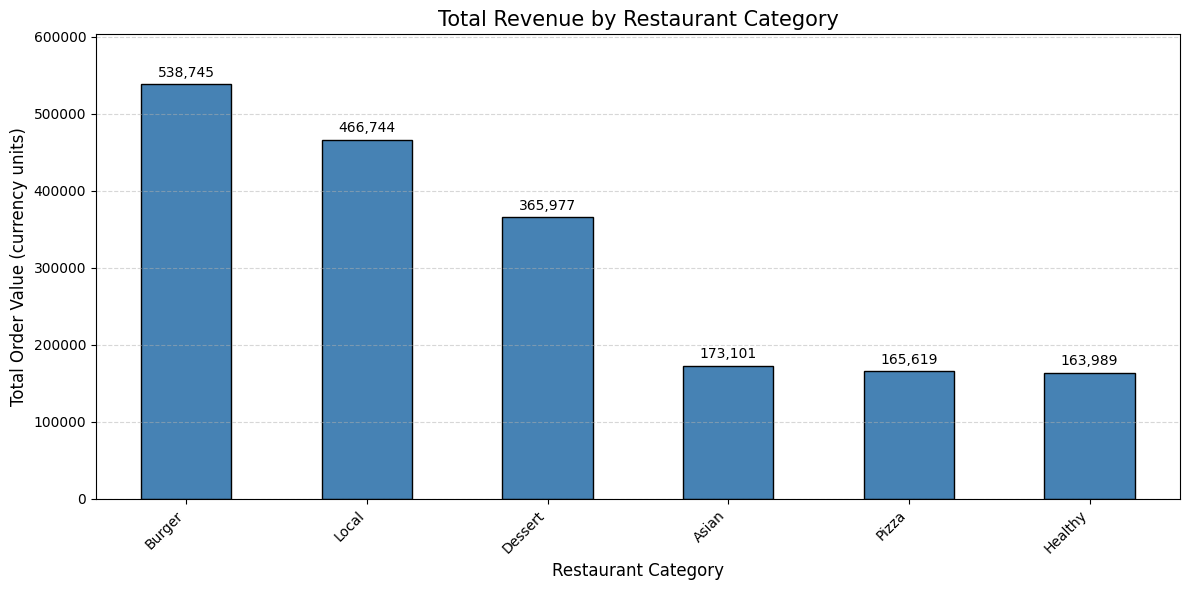

In [40]:
plt.figure(figsize=(12, 6))

ax = category_revenue.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Total Revenue by Restaurant Category', fontsize=15)
plt.xlabel('Restaurant Category', fontsize=12)
plt.ylabel('Total Order Value (currency units)', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Display values above each bar with commas
ax.bar_label(
    ax.containers[0],
    labels=[f'{value:,.0f}' for value in category_revenue.values],
    padding=3
)

plt.ylim(0, category_revenue.max() * 1.12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: Burger category generates the highest total revenue, followed by Local and Dessert categories. Asian, Pizza, and Healthy categories contribute comparatively less revenue.This may be because burgers are convenient and popular food choices, and some burger meals may require relatively short preparation times, encouraging customers to order them more frequently.

2. Which payment methods are associated with the highest total sales?

In [41]:
completed_df = df[df['order_status'] == 'Completed'].copy()

payment_sales = (
    completed_df.groupby('payment_method')['order_total']
    .sum()
    .sort_values(ascending=False)
)

print("Total Sales by Payment Method:")
print(payment_sales.round(2))

print("\nPayment method with the highest total sales:")
print(payment_sales.idxmax(), "-", round(payment_sales.max(), 2))

Total Sales by Payment Method:
payment_method
Credit Card       932702.68
Cash              571546.49
Digital Wallet    369927.40
Name: order_total, dtype: float64

Payment method with the highest total sales:
Credit Card - 932702.68


C:\Users\Gokul\AppData\Local\Temp\ipykernel_2496\1387852965.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  completed_df.groupby('payment_method')['order_total']


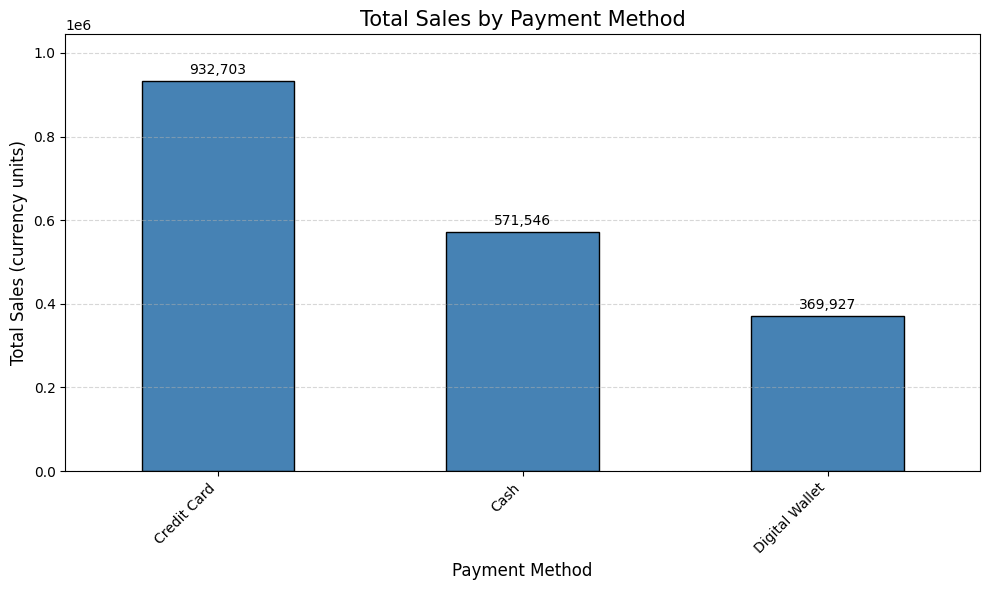

In [44]:
plt.figure(figsize=(10, 6))

ax = payment_sales.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Total Sales by Payment Method', fontsize=15)
plt.xlabel('Payment Method', fontsize=12)
plt.ylabel('Total Sales (currency units)', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Display values above the bars
ax.bar_label(
    ax.containers[0],
    labels=[f'{value:,.0f}' for value in payment_sales.values],
    padding=3
)

plt.ylim(0, payment_sales.max() * 1.12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: Credit Card payments generate the highest total sales, at approximately 930,000 currency units, followed by Cash at around 570,000 and Digital Wallet at approximately 370,000. This indicates that credit card payments contribute the largest share of sales among the three payment methods. This may be because of convenience, cashless payment preferences, and available card benefits.

3. Which day of the week generates the most orders?

In [46]:
weekday_orders = (
    df.groupby('day_of_week')['order_id']
    .nunique()
)

# Arrange weekdays in calendar order
weekday_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

weekday_orders = weekday_orders.reindex(weekday_order)

print("Number of Orders by Day of the Week:")
print(weekday_orders)

print("\nDay with the Highest Number of Orders:")
print(weekday_orders.idxmax(), "-", weekday_orders.max(), "orders")

Number of Orders by Day of the Week:
day_of_week
Monday       6665
Tuesday      6671
Wednesday    8212
Thursday     8472
Friday       6624
Saturday     6698
Sunday       6658
Name: order_id, dtype: int64

Day with the Highest Number of Orders:
Thursday - 8472 orders


C:\Users\Gokul\AppData\Local\Temp\ipykernel_2496\3648344938.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('day_of_week')['order_id']


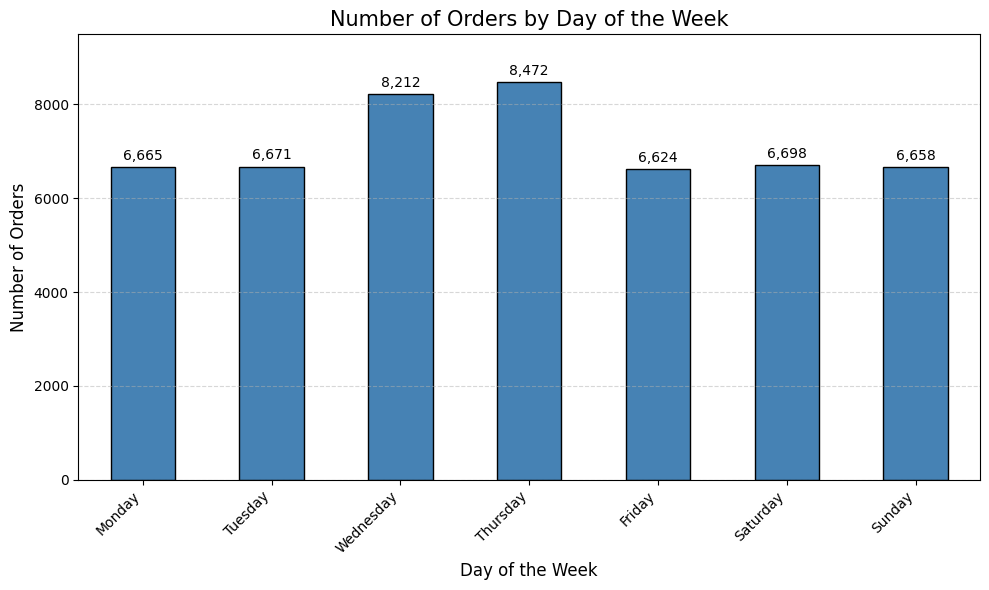

In [47]:
plt.figure(figsize=(10, 6))

ax = weekday_orders.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Number of Orders by Day of the Week', fontsize=15)
plt.xlabel('Day of the Week', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Display values above each bar
ax.bar_label(
    ax.containers[0],
    labels=[f'{value:,.0f}' for value in weekday_orders.values],
    padding=3
)

plt.ylim(0, weekday_orders.max() * 1.12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: Thursday generates the highest number of orders, with 8,472 orders, followed by Wednesday with 8,212 orders. Saturday records 6,698 orders, while Tuesday and Sunday have 6,671 and 6,658 orders, respectively. Friday has the lowest order volume, with 6,624 orders.
This may be because of customers' work schedules, meal routines, or other purchasing habits. 

4. How does order volume vary between weekdays and weekends?


In [48]:
# Group orders into weekdays and weekends
day_type_orders = (
    df.groupby('is_weekend')['order_id']
    .nunique()
    .rename(index={False: 'Weekday', True: 'Weekend'})
    .reindex(['Weekday', 'Weekend'])
)

print("Number of Orders: Weekdays vs Weekends")
print(day_type_orders)

print("\nPercentage of Total Orders:")
print((day_type_orders / day_type_orders.sum() * 100).round(2))

Number of Orders: Weekdays vs Weekends
is_weekend
Weekday    36644
Weekend    13356
Name: order_id, dtype: int64

Percentage of Total Orders:
is_weekend
Weekday    73.29
Weekend    26.71
Name: order_id, dtype: float64


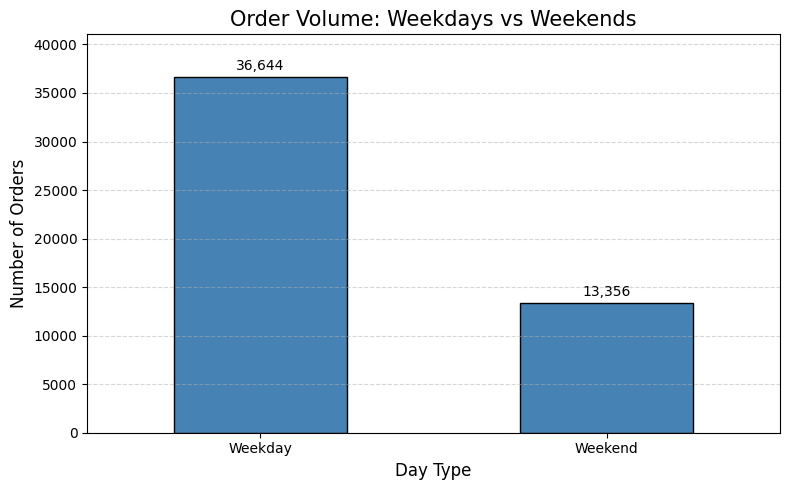

In [49]:
plt.figure(figsize=(8, 5))

ax = day_type_orders.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Order Volume: Weekdays vs Weekends', fontsize=15)
plt.xlabel('Day Type', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.xticks(rotation=0)

# Display values above each bar
ax.bar_label(
    ax.containers[0],
    labels=[f'{value:,.0f}' for value in day_type_orders.values],
    padding=3
)

plt.ylim(0, day_type_orders.max() * 1.12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: weekdays generate significantly more orders than weekends. Weekdays account for 36,644 orders (approximately 73.29%), while weekends account for 13,356 orders (approximately 26.71%).This difference may be related to customers ordering food during working days because of busy schedules, limited time for cooking, or workplace meal needs. Weekend demand may be lower because some customers prefer home-cooked meals or dining out. 

5. Which meal periods generate the highest revenue?

In [50]:

# Classify orders based on order_hour
conditions = [
    df['order_hour'].between(6, 10),
    df['order_hour'].between(11, 14),
    df['order_hour'].between(15, 17),
    df['order_hour'].between(18, 22)
]

meal_periods = ['Breakfast', 'Lunch', 'Evening', 'Dinner']

df['meal_period'] = np.select(
    conditions,
    meal_periods,
    default='Other'
)

# Calculate revenue from completed orders only
completed_df = df[df['order_status'] == 'Completed'].copy()

meal_revenue = (
    completed_df.groupby('meal_period')['order_total']
    .sum()
    .reindex(['Breakfast', 'Lunch', 'Evening', 'Dinner', 'Other'])
)

print("Total Revenue by Meal Period:")
print(meal_revenue.round(2))

print("\nMeal Period with Highest Revenue:")
print(meal_revenue.idxmax(), "-", round(meal_revenue.max(), 2))

Total Revenue by Meal Period:
meal_period
Breakfast    319871.23
Lunch        545762.35
Evening      203891.55
Dinner       673846.63
Other        130804.81
Name: order_total, dtype: float64

Meal Period with Highest Revenue:
Dinner - 673846.63


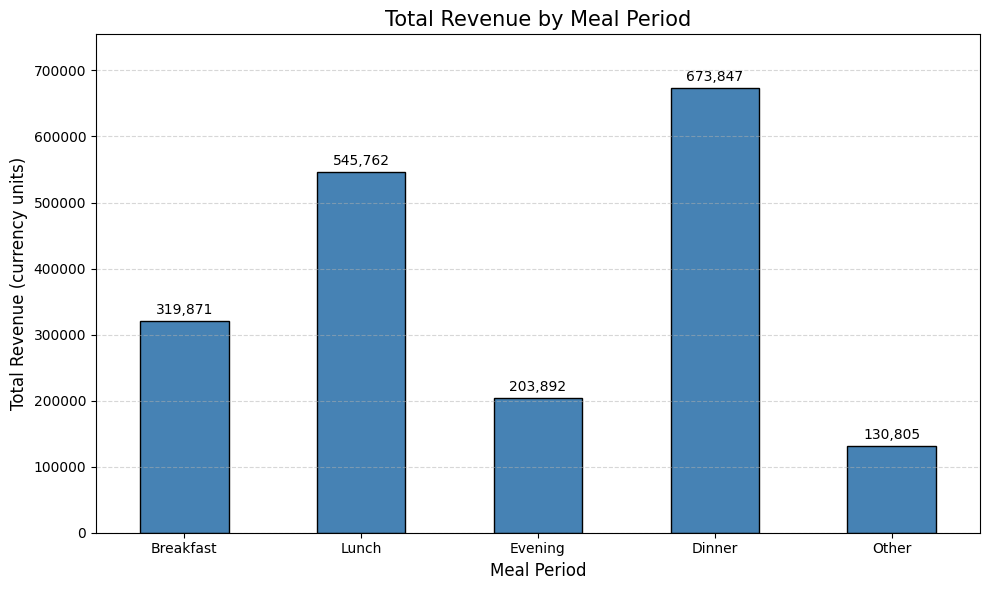

In [52]:
plt.figure(figsize=(10, 6))

ax = meal_revenue.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Total Revenue by Meal Period', fontsize=15)
plt.xlabel('Meal Period', fontsize=12)
plt.ylabel('Total Revenue (currency units)', fontsize=12)
plt.xticks(rotation=0)

# Display values above bars
ax.bar_label(
    ax.containers[0],
    labels=[f'{value:,.0f}' for value in meal_revenue.values],
    padding=3
)

plt.ylim(0, meal_revenue.max() * 1.12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: Dinner generates the highest revenue (673,847 currency units), followed by lunch (545,762),. Breakfast contributes approximately (319,871), while evening generates around (203,892). The Other category, covering overnight hours, records the lowest revenue at approximately (130,805) currency units.Dinner's leading revenue may be associated with customers ordering their main evening meals after work or spending more per order during this period. Lunch also generates substantial revenue, potentially due to midday meal demand.

6. Which customer types generate the highest total revenue?

In [53]:
completed_df = df[df['order_status'] == 'Completed'].copy()

customer_type_revenue = (
    completed_df.groupby('customer_type')['order_total']
    .sum()
    .sort_values(ascending=False)
)

print("Total Revenue by Customer Type:")
print(customer_type_revenue.round(2))

print("\nCustomer Type with Highest Revenue:")
print(
    customer_type_revenue.idxmax(),
    "-",
    round(customer_type_revenue.max(), 2)
)

Total Revenue by Customer Type:
customer_type
Regular    977149.10
Premium    489486.50
New        407540.97
Name: order_total, dtype: float64

Customer Type with Highest Revenue:
Regular - 977149.1


C:\Users\Gokul\AppData\Local\Temp\ipykernel_2496\3936103107.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  completed_df.groupby('customer_type')['order_total']


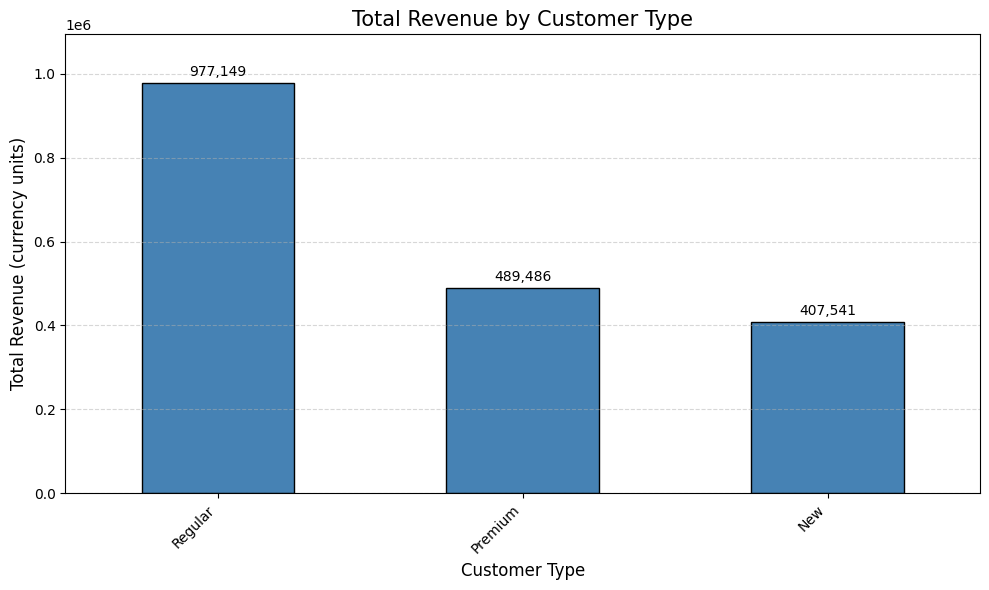

In [55]:
plt.figure(figsize=(10, 6))

ax = customer_type_revenue.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Total Revenue by Customer Type', fontsize=15)
plt.xlabel('Customer Type', fontsize=12)
plt.ylabel('Total Revenue (currency units)', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Display values above bars
ax.bar_label(
    ax.containers[0],
    labels=[f'{value:,.0f}' for value in customer_type_revenue.values],
    padding=3
)

plt.ylim(0, customer_type_revenue.max() * 1.12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: Regular customers generate the highest revenue (977,149 currency units) because they may order more frequently due to familiarity with the platform and established ordering habits, while premium and new customers contribute less overall revenue.

7. How does order frequency vary across customer age groups?

In [57]:

# Create age groups
age_bins = [0, 25, 35, 45, 55, float('inf')]
age_labels = ['18-25', '26-35', '36-45', '46-55', '56+']

df['age_group'] = pd.cut(
    df['customer_age'],
    bins=age_bins,
    labels=age_labels,
    right=True
)

# Count orders for each age group
age_group_orders = (
    df.groupby('age_group', observed=False)['order_id']
    .nunique()
    .reindex(age_labels)
)

print("Number of Orders by Customer Age Group:")
print(age_group_orders)

print("\nAge Group with the Highest Number of Orders:")
print(age_group_orders.idxmax(), "-", age_group_orders.max(), "orders")

Number of Orders by Customer Age Group:
age_group
18-25    21252
26-35    18715
36-45     9757
46-55      276
56+          0
Name: order_id, dtype: int64

Age Group with the Highest Number of Orders:
18-25 - 21252 orders


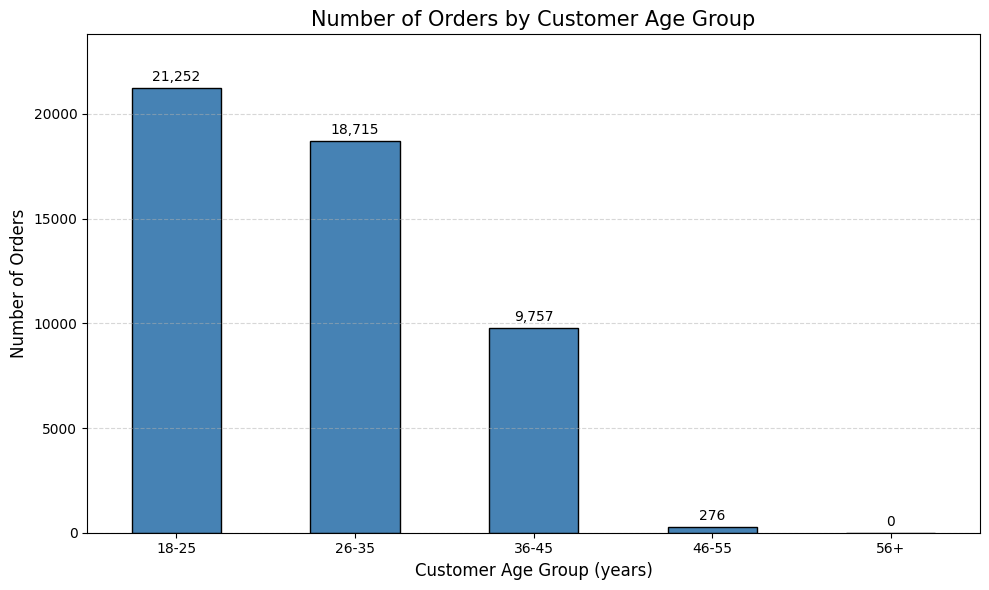

In [58]:
plt.figure(figsize=(10, 6))

ax = age_group_orders.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Number of Orders by Customer Age Group', fontsize=15)
plt.xlabel('Customer Age Group (years)', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.xticks(rotation=0)

# Display values above bars
ax.bar_label(
    ax.containers[0],
    labels=[f'{value:,.0f}' for value in age_group_orders.values],
    padding=3
)

plt.ylim(0, age_group_orders.max() * 1.12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: Customers aged 18–25 generate the highest order volume (21,252 orders), followed by the 26–35 age group (18,715 orders).
Younger customers may be more familiar with digital ordering platforms, convenience-oriented lifestyles, and frequent use of food delivery services. 

8. What percentage of orders comes from each customer type?

In [59]:
customer_type_percentage = (
    df['customer_type']
    .value_counts(normalize=True)
    .mul(100)
)

print("Percentage of Orders by Customer Type:")
print(customer_type_percentage.round(2))

Percentage of Orders by Customer Type:
customer_type
Regular    50.20
Premium    29.45
New        20.35
Name: proportion, dtype: float64


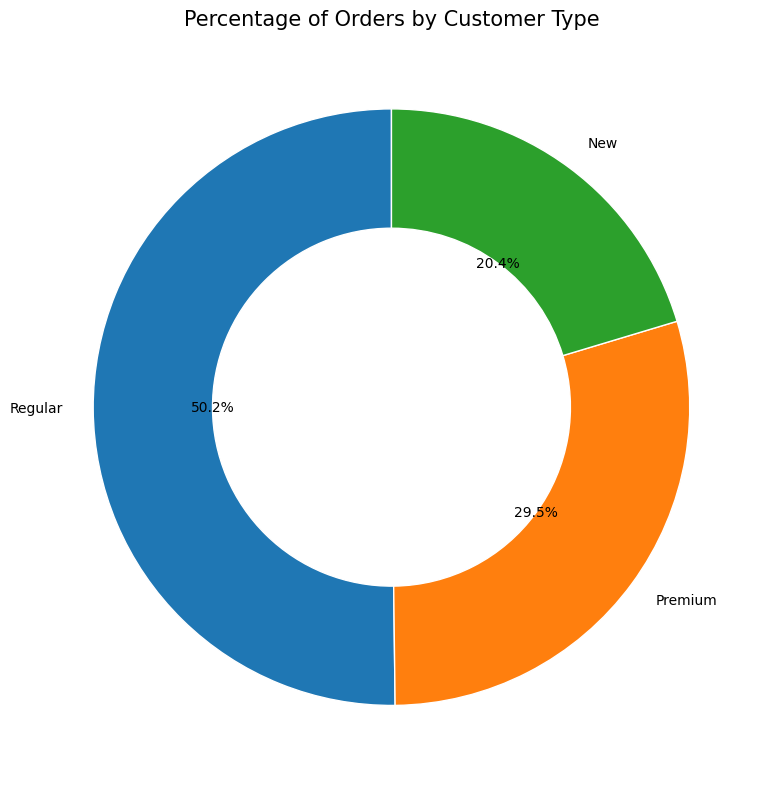

In [60]:
plt.figure(figsize=(8, 8))

plt.pie(
    customer_type_percentage,
    labels=customer_type_percentage.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width': 0.4, 'edgecolor': 'white'}
)

plt.title('Percentage of Orders by Customer Type', fontsize=15)
plt.tight_layout()
plt.show()

Conclusion: Regular customers contribute the highest percentage of orders, accounting for 50.2% of all orders. Premium customers contribute 29.5%, while New customers account for 20.3%. This suggests that regular customers form the main user base of the food delivery platform, potentially due to repeat ordering habits and familiarity with the service.

9. Which restaurant categories receive the highest average customer ratings?

In [61]:
completed_df = df[df['order_status'] == 'Completed'].copy()

category_ratings = (
    completed_df.groupby('restaurant_primary_category')['customer_rating']
    .mean()
    .sort_values(ascending=False)
)

print("Average Customer Rating by Restaurant Category:")
print(category_ratings.round(2))

print("\nTop-Rated Restaurant Category:")
print(category_ratings.idxmax(), "-", round(category_ratings.max(), 2))

Average Customer Rating by Restaurant Category:
restaurant_primary_category
Healthy    4.32
Burger     4.30
Asian      4.30
Dessert    4.30
Local      4.29
Pizza      4.28
Name: customer_rating, dtype: float64

Top-Rated Restaurant Category:
Healthy - 4.32


C:\Users\Gokul\AppData\Local\Temp\ipykernel_2496\3970159861.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  completed_df.groupby('restaurant_primary_category')['customer_rating']


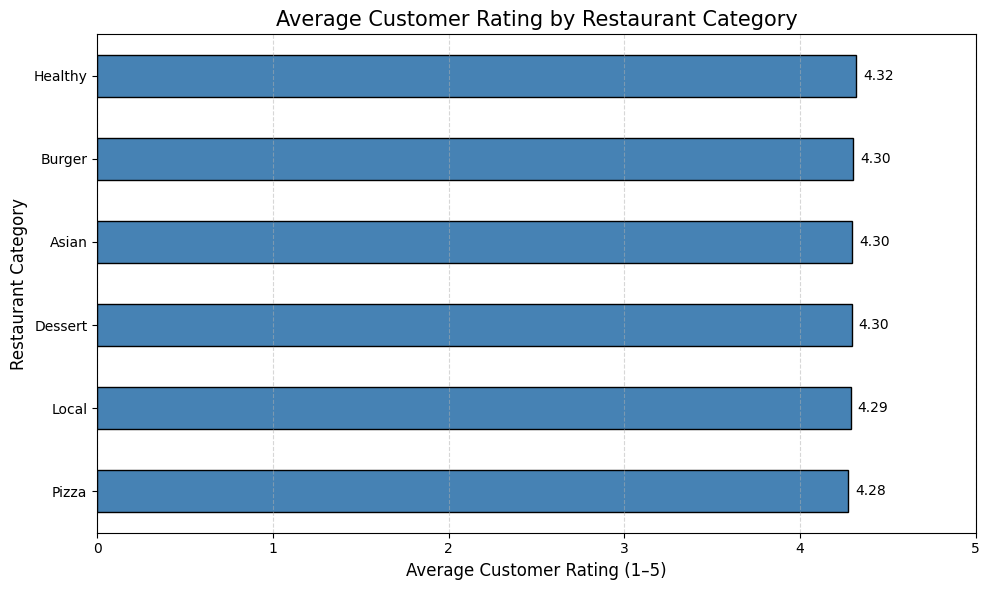

In [62]:
plt.figure(figsize=(10, 6))

ax = category_ratings.sort_values().plot(
    kind='barh',
    color='steelblue',
    edgecolor='black'
)

plt.title('Average Customer Rating by Restaurant Category', fontsize=15)
plt.xlabel('Average Customer Rating (1–5)', fontsize=12)
plt.ylabel('Restaurant Category', fontsize=12)
plt.xlim(0, 5)

# Display rating values
ax.bar_label(
    ax.containers[0],
    fmt='%.2f',
    padding=5
)

plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: The Healthy restaurant category has the highest average customer rating at 4.32/5, while Pizza has the lowest at 4.28/5.
All categories receive ratings around 4.3.The differences between categories are very small, indicating that customer satisfaction is consistently high across all six restaurant categories. Healthy restaurants may perform slightly better because of food quality, customer preferences, or overall ordering experiences. 

10. Which restaurant types have the highest average number of items per order?

In [63]:
completed_df = df[df['order_status'] == 'Completed'].copy()

restaurant_items = (
    completed_df.groupby('restaurant_type')['items_count']
    .mean()
    .sort_values(ascending=False)
)

print("Average Number of Items per Order by Restaurant Type:")
print(restaurant_items.round(2))

print("\nRestaurant Type with Highest Average Items:")
print(restaurant_items.idxmax(), "-", round(restaurant_items.max(), 2))

Average Number of Items per Order by Restaurant Type:
restaurant_type
Fast Food        2.92
Cafe             2.91
Casual Dining    2.89
Fine Dining      2.85
Name: items_count, dtype: float64

Restaurant Type with Highest Average Items:
Fast Food - 2.92


C:\Users\Gokul\AppData\Local\Temp\ipykernel_2496\2347702356.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  completed_df.groupby('restaurant_type')['items_count']


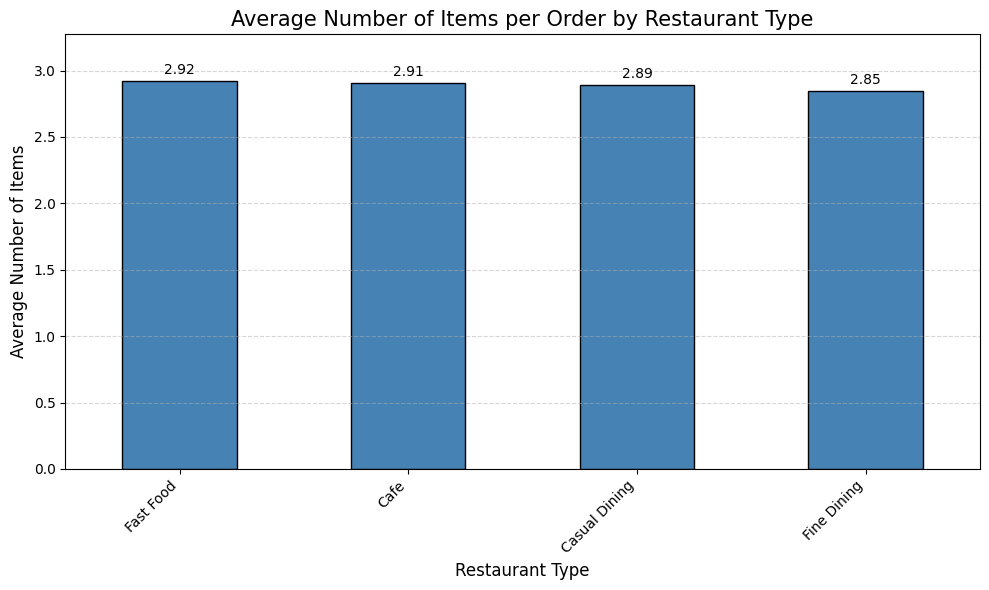

In [64]:
plt.figure(figsize=(10, 6))

ax = restaurant_items.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Average Number of Items per Order by Restaurant Type', fontsize=15)
plt.xlabel('Restaurant Type', fontsize=12)
plt.ylabel('Average Number of Items', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Display values above bars
ax.bar_label(
    ax.containers[0],
    fmt='%.2f',
    padding=3
)

plt.ylim(0, restaurant_items.max() * 1.12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: Fast Food restaurants have the highest average number of items per order, at approximately 2.92 items, closely followed by Cafes at around 2.91 items. Casual Dining averages approximately 2.89 items, while Fine Dining has the lowest average at around 2.85 items.
The differences between restaurant types are very small, indicating that customers order approximately three items per order across all four types. Fast Food restaurants may have a slightly higher average because customers often purchase combinations of main items, sides, and drinks. Fine Dining's marginally lower average may reflect differences in menu structure or ordering patterns.

11. Which traffic conditions are associated with the longest actual delivery times?

In [65]:
completed_df = df[df['order_status'] == 'Completed'].copy()

traffic_delivery = (
    completed_df.groupby('traffic_level')['actual_delivery_time_minutes']
    .mean()
    .sort_values(ascending=False)
)

print("Average Actual Delivery Time by Traffic Level:")
print(traffic_delivery.round(2))

print("\nTraffic Condition with the Longest Average Delivery Time:")
print(traffic_delivery.idxmax(), "-", round(traffic_delivery.max(), 2), "minutes")

Average Actual Delivery Time by Traffic Level:
traffic_level
High      39.89
Medium    35.02
Low       30.59
Name: actual_delivery_time_minutes, dtype: float64

Traffic Condition with the Longest Average Delivery Time:
High - 39.89 minutes


C:\Users\Gokul\AppData\Local\Temp\ipykernel_2496\809039978.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  completed_df.groupby('traffic_level')['actual_delivery_time_minutes']


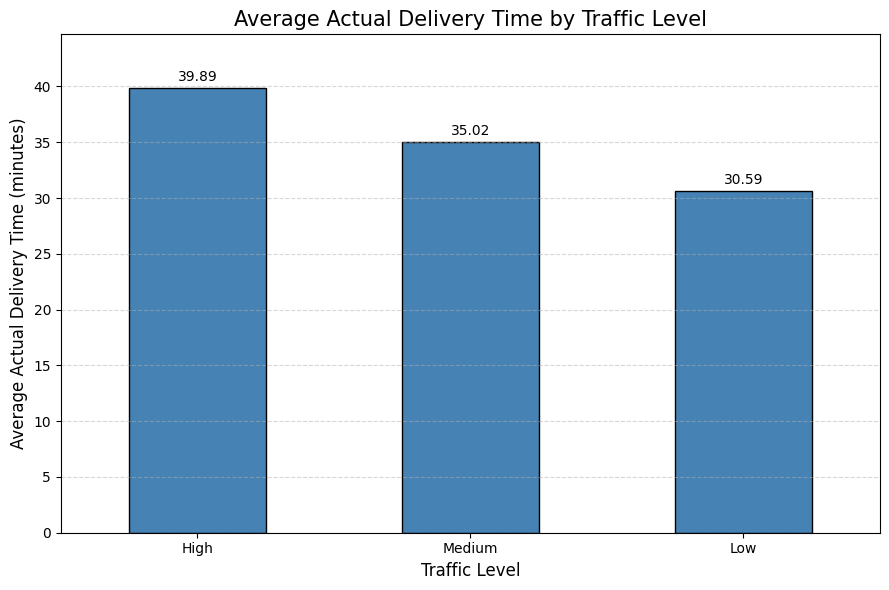

In [66]:
plt.figure(figsize=(9, 6))

ax = traffic_delivery.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Average Actual Delivery Time by Traffic Level', fontsize=15)
plt.xlabel('Traffic Level', fontsize=12)
plt.ylabel('Average Actual Delivery Time (minutes)', fontsize=12)
plt.xticks(rotation=0)

# Display values above bars
ax.bar_label(
    ax.containers[0],
    fmt='%.2f',
    padding=3
)

plt.ylim(0, traffic_delivery.max() * 1.12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: High traffic has the longest average delivery time at 39.89 minutes, followed by medium traffic at 35.02 minutes and low traffic at 30.59 minutes. This indicates that heavier traffic is associated with longer delivery times, likely due to road congestion and slower travel speeds.

12. How does weather affect average delivery time?

In [67]:
completed_df = df[df['order_status'] == 'Completed'].copy()

weather_delivery = (
    completed_df.groupby('weather')['actual_delivery_time_minutes']
    .mean()
    .sort_values(ascending=False)
)

print("Average Actual Delivery Time by Weather:")
print(weather_delivery.round(2))

print("\nWeather Condition with the Longest Average Delivery Time:")
print(
    weather_delivery.idxmax(),
    "-",
    round(weather_delivery.max(), 2),
    "minutes"
)

Average Actual Delivery Time by Weather:
weather
Storm     47.07
Rain      39.16
Cloudy    35.12
Clear     33.56
Name: actual_delivery_time_minutes, dtype: float64

Weather Condition with the Longest Average Delivery Time:
Storm - 47.07 minutes


C:\Users\Gokul\AppData\Local\Temp\ipykernel_2496\4051153946.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  completed_df.groupby('weather')['actual_delivery_time_minutes']


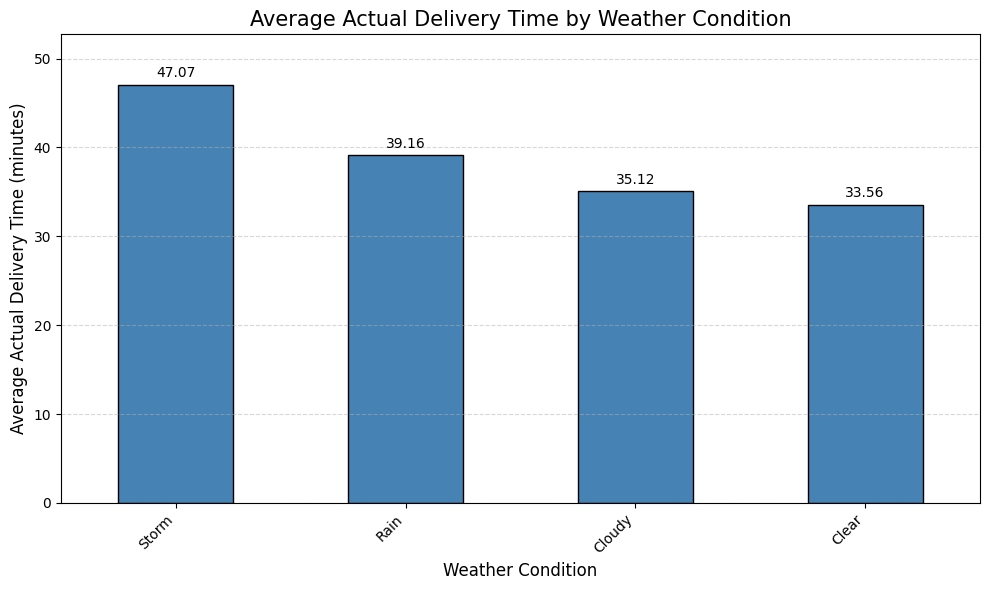

In [68]:
plt.figure(figsize=(10, 6))

ax = weather_delivery.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Average Actual Delivery Time by Weather Condition', fontsize=15)
plt.xlabel('Weather Condition', fontsize=12)
plt.ylabel('Average Actual Delivery Time (minutes)', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Display values above bars
ax.bar_label(
    ax.containers[0],
    fmt='%.2f',
    padding=3
)

plt.ylim(0, weather_delivery.max() * 1.12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: Stormy weather has the longest average delivery time at 47.07 minutes, followed by rain at 39.16 minutes, cloudy conditions at 35.12 minutes, and clear weather at 33.56 minutes. This pattern suggests that adverse weather conditions are associated with longer delivery times. Poor weather may cause delays due to reduced road visibility, slippery roads, slower travel speeds, make driving more difficult, and force delivery partners to travel more cautiously. Rain can also affect road conditions and traffic flow. In contrast, clear weather generally provides more favourable conditions for travel, which may help drivers complete deliveries faster.

13. What percentage of orders are delivered late?

In [69]:

# Keep orders with valid actual delivery time and late-delivery status
valid_delivery_df = df[
    df['actual_delivery_time_minutes'].notna()
    & df['late_delivery'].notna()
].copy()

# Calculate late and on-time order counts
late_counts = (
    valid_delivery_df['late_delivery']
    .astype(int)
    .value_counts()
    .reindex([1, 0], fill_value=0)
)

late_count = late_counts.loc[1]
on_time_count = late_counts.loc[0]
total_valid_orders = late_count + on_time_count

late_percentage = late_count / total_valid_orders * 100
on_time_percentage = on_time_count / total_valid_orders * 100

print("Total orders with valid delivery data:", total_valid_orders)
print("Late orders:", late_count)
print("On-time orders:", on_time_count)
print(f"Late delivery percentage: {late_percentage:.2f}%")
print(f"On-time delivery percentage: {on_time_percentage:.2f}%")

Total orders with valid delivery data: 49132
Late orders: 17968
On-time orders: 31164
Late delivery percentage: 36.57%
On-time delivery percentage: 63.43%


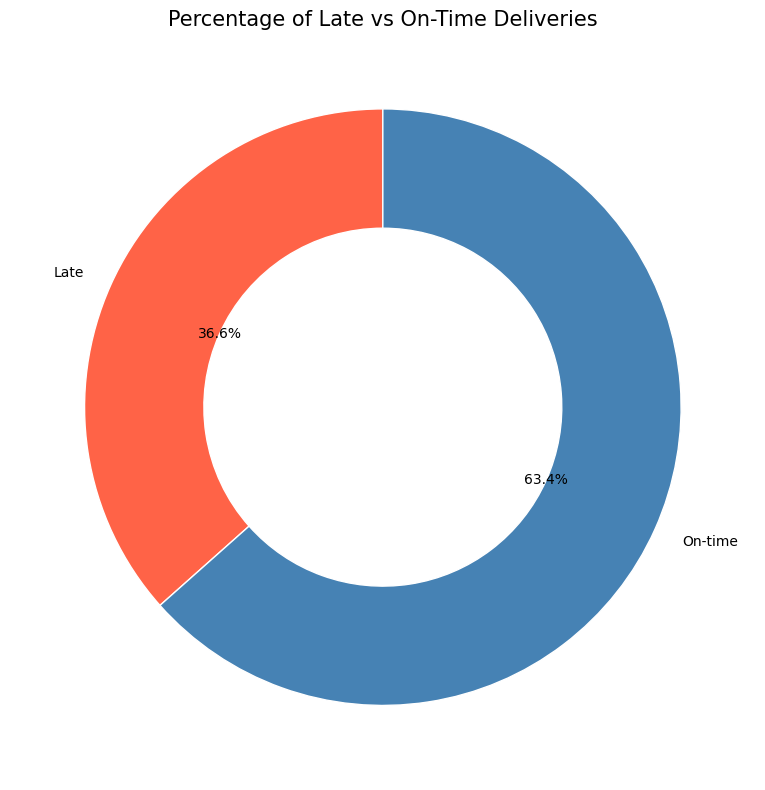

In [70]:
labels = ['Late', 'On-time']
values = [late_count, on_time_count]

plt.figure(figsize=(8, 8))

plt.pie(
    values,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=['tomato', 'steelblue'],
    wedgeprops={'width': 0.4, 'edgecolor': 'white'}
)

plt.title('Percentage of Late vs On-Time Deliveries', fontsize=15)
plt.tight_layout()
plt.show()

Conclusion: 36.6% of valid deliveries are late, while 63.4% are delivered on time. This means that more than one-third of completed deliveries exceed the dataset's defined lateness threshold, indicating a notable delivery-performance challenge.
Possible reason for late deliveries are heavy traffic, Adverse weather conditions.

14. How does delivery distance affect actual delivery time?

In [72]:
completed_df = df[
    (df['order_status'] == 'Completed') &
    (df['actual_delivery_time_minutes'].notna()) &
    (df['distance_km'].notna())
].copy()

# Calculate correlation
correlation = completed_df['distance_km'].corr(
    completed_df['actual_delivery_time_minutes']
)

print("Correlation between Distance and Actual Delivery Time:",
      round(correlation, 3))

Correlation between Distance and Actual Delivery Time: 0.767


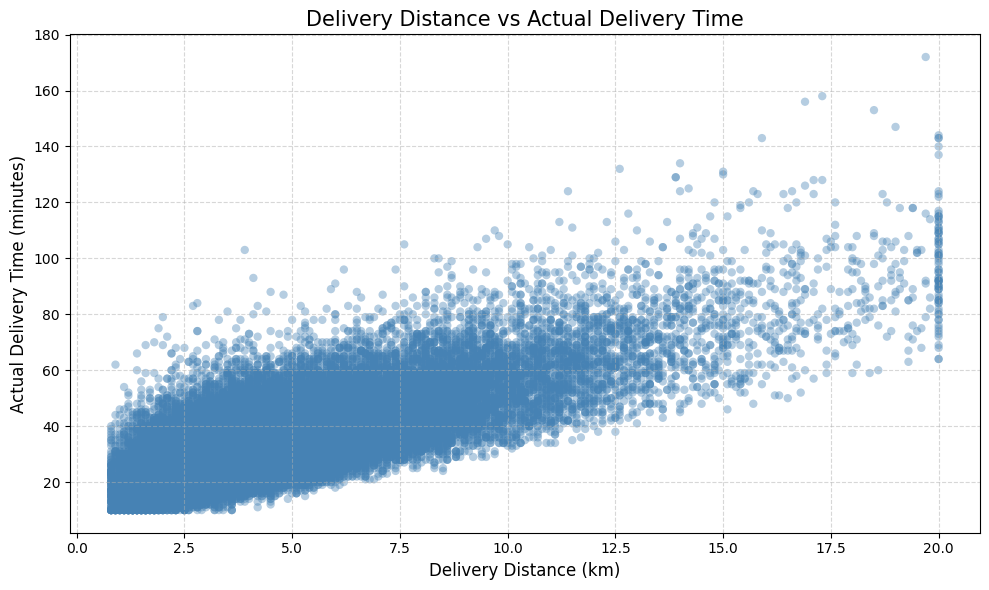

In [73]:
plt.figure(figsize=(10, 6))

plt.scatter(
    completed_df['distance_km'],
    completed_df['actual_delivery_time_minutes'],
    color='steelblue',
    edgecolor='none',
    alpha=0.4
)

plt.title('Delivery Distance vs Actual Delivery Time', fontsize=15)
plt.xlabel('Delivery Distance (km)', fontsize=12)
plt.ylabel('Actual Delivery Time (minutes)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: The scatter plot shows a positive relationship between delivery distance and actual delivery time. Actual delivery time generally increases as delivery distance increases, with longer-distance orders often taking more time to complete. This may be because drivers need more travel time to reach customers, while traffic and road conditions can cause additional delays.

15. What percentage of orders are completed versus cancelled?

In [74]:

# Count orders by status
status_counts = df['order_status'].value_counts()

# Calculate percentages
status_percentages = (
    df['order_status'].value_counts(normalize=True) * 100
)

print("Order Counts by Status:")
print(status_counts)

print("\nOrder Status Percentages:")
print(status_percentages.round(2))

Order Counts by Status:
order_status
Completed    49132
Cancelled      868
Name: count, dtype: int64

Order Status Percentages:
order_status
Completed    98.26
Cancelled     1.74
Name: proportion, dtype: float64


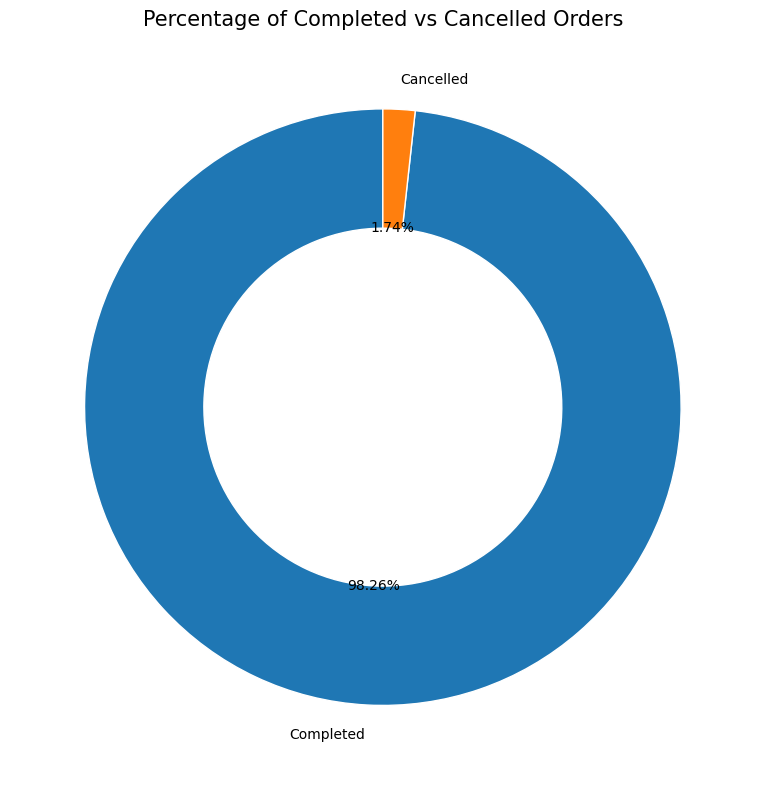

In [75]:
plt.figure(figsize=(8, 8))

plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct='%1.2f%%',
    startangle=90,
    wedgeprops={'width': 0.4, 'edgecolor': 'white'}
)

plt.title('Percentage of Completed vs Cancelled Orders', fontsize=15)
plt.tight_layout()
plt.show()

Conclusion: The dataset shows that 98.26% of orders are completed, while only 1.74% are cancelled. This indicates a high order completion rate, suggesting that most orders are successfully fulfilled by the food delivery platform.

16. What are the most common reasons for order cancellations?

In [76]:

# Filter cancelled orders only
cancelled_df = df[df['order_status'] == 'Cancelled'].copy()

# Count cancellation reasons
cancellation_counts = (
    cancelled_df['cancellation_reason']
    .value_counts()
    .sort_values(ascending=False)
)

print("Order Cancellation Reasons:")
print(cancellation_counts)

print("\nPercentage of Cancelled Orders by Reason:")
print(
    (cancellation_counts / len(cancelled_df) * 100).round(2)
)

print("\nMost Common Cancellation Reason:")
print(cancellation_counts.idxmax(), "-", cancellation_counts.max(), "orders")

Order Cancellation Reasons:
cancellation_reason
Driver Unassigned         386
Restaurant Unavailable    160
Customer Cancelled        154
Changed Mind              153
Long Prep Delay            15
Name: count, dtype: int64

Percentage of Cancelled Orders by Reason:
cancellation_reason
Driver Unassigned         44.47
Restaurant Unavailable    18.43
Customer Cancelled        17.74
Changed Mind              17.63
Long Prep Delay            1.73
Name: count, dtype: float64

Most Common Cancellation Reason:
Driver Unassigned - 386 orders


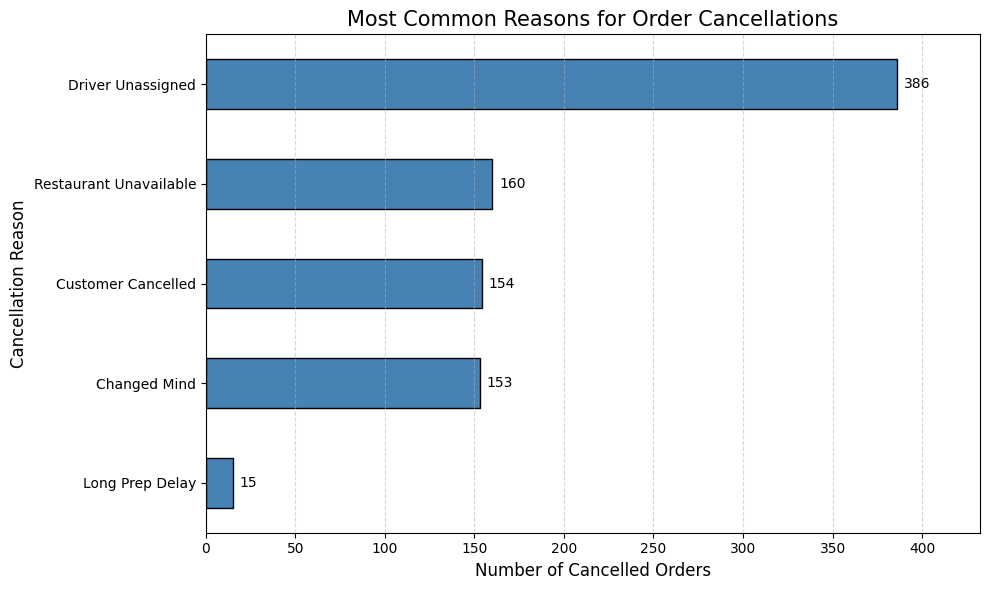

In [78]:
plt.figure(figsize=(10, 6))

ax = cancellation_counts.sort_values().plot(
    kind='barh',
    color='steelblue',
    edgecolor='black'
)

plt.title('Most Common Reasons for Order Cancellations', fontsize=15)
plt.xlabel('Number of Cancelled Orders', fontsize=12)
plt.ylabel('Cancellation Reason', fontsize=12)

# Display values at the end of each bar
ax.bar_label(
    ax.containers[0],
    fmt='%.0f',
    padding=5
)

plt.xlim(0, cancellation_counts.max() * 1.12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: Driver unavailability is the leading reason for order cancellations, accounting for 386 orders, followed by restaurant unavailability (160) and customer cancellations (154). 
The results suggest that delivery-partner assignment is the main operational issue associated with cancellations in this dataset. When a driver is not assigned, an order may be unable to proceed to delivery. Restaurant unavailability also contributes to cancellations, potentially because restaurants cannot fulfil orders when required. Customer cancellations and changes of mind represent another substantial group, while long preparation delays account for comparatively few cases.

17. How does delivery lateness affect customer ratings?

In [79]:

# Filter completed orders with valid customer ratings
valid_df = df[
    (df['order_status'] == 'Completed') &
    (df['late_delivery'].notna()) &
    (df['customer_rating'].notna())
].copy()

# Calculate average rating by delivery status
rating_by_lateness = (
    valid_df.groupby('late_delivery')['customer_rating']
    .mean()
    .rename(index={0: 'On-time', 1: 'Late'})
    .reindex(['On-time', 'Late'])
)

print("Average Customer Rating by Delivery Status:")
print(rating_by_lateness.round(2))

print("\nRating Difference (On-time - Late):",
      round(rating_by_lateness['On-time'] - rating_by_lateness['Late'], 2))

Average Customer Rating by Delivery Status:
late_delivery
On-time    4.56
Late       3.83
Name: customer_rating, dtype: float64

Rating Difference (On-time - Late): 0.73


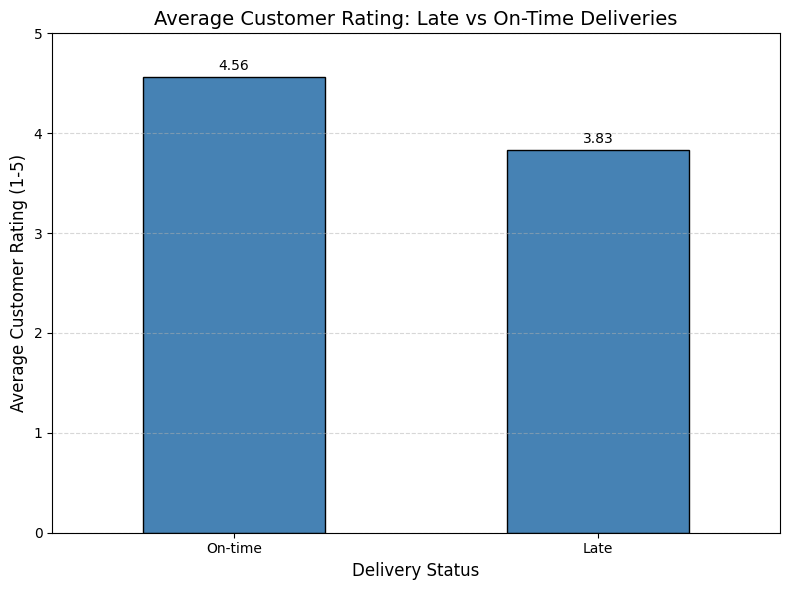

In [80]:
plt.figure(figsize=(8, 6))

ax = rating_by_lateness.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Average Customer Rating: Late vs On-Time Deliveries', fontsize=14)
plt.xlabel('Delivery Status', fontsize=12)
plt.ylabel('Average Customer Rating (1-5)', fontsize=12)
plt.ylim(0, 5)
plt.xticks(rotation=0)

# Display rating values
ax.bar_label(
    ax.containers[0],
    fmt='%.2f',
    padding=3
)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: On-time deliveries receive a higher average customer rating of 4.56/5, compared with 3.83/5 for late deliveries. This suggests that timely delivery improves customer satisfaction, while delays may negatively affect the customer experience.

18. How does restaurant preparation time vary across restaurant types?

In [81]:
restaurant_prep = (
    df.groupby('restaurant_type')['restaurant_preparation_time_minutes']
      .mean()
      .sort_values()
)

print(restaurant_prep)

restaurant_type
Cafe             11.868673
Fast Food        14.443482
Casual Dining    18.968843
Fine Dining      28.687708
Name: restaurant_preparation_time_minutes, dtype: float64


C:\Users\Gokul\AppData\Local\Temp\ipykernel_2496\1277396962.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('restaurant_type')['restaurant_preparation_time_minutes']


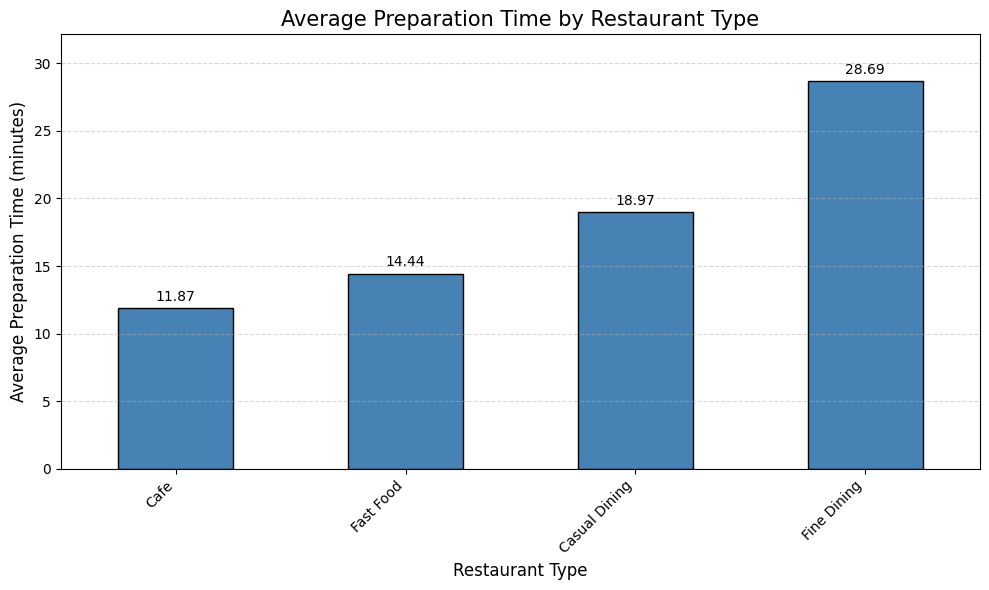

In [82]:
plt.figure(figsize=(10, 6))

ax = restaurant_prep.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Average Preparation Time by Restaurant Type', fontsize=15)
plt.xlabel('Restaurant Type', fontsize=12)
plt.ylabel('Average Preparation Time (minutes)', fontsize=12)
plt.xticks(rotation=45, ha='right')

ax.bar_label(ax.containers[0], fmt='%.2f', padding=3)

plt.ylim(0, restaurant_prep.max() * 1.12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: Fine Dining has the highest average preparation time at 28.69 minutes, followed by Casual Dining (18.97), Fast Food (14.44), and Cafes (11.87). Fine Dining may require longer preparation due to more elaborate dishes and complex cooking processes, while Cafes typically serve items that are quicker to prepare.

19. How does delivery partner experience relate to delivery partner ratings?

In [85]:
driver_experience_rating = (
    df.groupby('delivery_partner_experience_months')
      ['delivery_partner_rating']
      .mean()
      .dropna()
      .sort_index()
)

print(driver_experience_rating)

delivery_partner_experience_months
1     4.721875
2     4.546785
3     5.000000
4     4.344970
5     4.330769
6     4.575749
7     4.249213
8     4.370111
9     4.200000
10    4.493805
11    4.000000
12    4.364020
13    4.700000
14    4.466720
15    4.651308
16    4.356936
18    4.500000
19    4.292372
20    4.459184
21    4.590574
22    4.594099
23    4.538759
24    4.364298
25    4.733075
27    4.452102
28    4.394714
29    4.393627
31    4.496257
32    4.600000
33    4.383630
34    4.693894
35    5.000000
36    4.586880
38    4.500000
39    4.588970
40    4.483215
41    4.430683
42    4.549617
43    4.513537
44    4.649119
45    4.454712
46    4.406966
47    4.149854
48    4.521862
49    5.000000
50    4.385245
51    4.867722
52    5.000000
53    4.328090
54    4.293398
55    4.429518
56    4.600000
57    4.900000
59    4.530460
60    4.521706
Name: delivery_partner_rating, dtype: float64


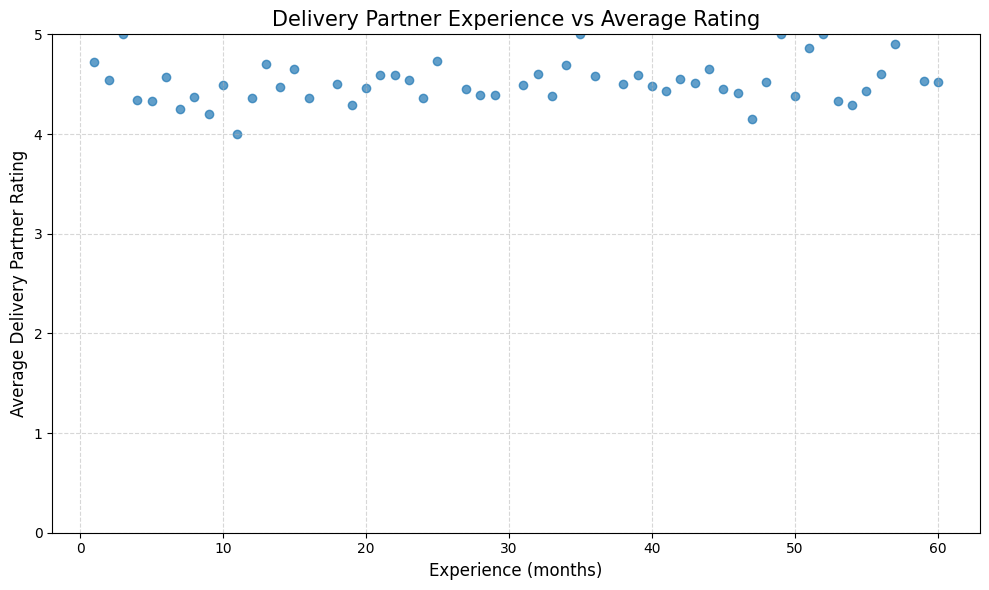

In [86]:
plt.figure(figsize=(10, 6))

plt.scatter(
    driver_experience_rating.index,
    driver_experience_rating.values,
    alpha=0.7
)

plt.title('Delivery Partner Experience vs Average Rating', fontsize=15)
plt.xlabel('Experience (months)', fontsize=12)
plt.ylabel('Average Delivery Partner Rating', fontsize=12)
plt.ylim(0, 5)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: Delivery partner ratings remain relatively consistent (mostly 4.3–4.8) across different experience levels, with no clear upward trend as experience increases. This suggests that experience alone may not strongly influence customer ratings.

20. Which customer types have the highest order cancellation rates?

In [89]:
# Count total orders and cancelled orders by customer type
customer_cancellations = df.groupby('customer_type').agg(
    total_orders=('order_id', 'count'),
    cancelled_orders=('order_status', lambda x: (x == 'Cancelled').sum())
)

# Calculate cancellation percentage
customer_cancellations['cancellation_rate'] = (
    customer_cancellations['cancelled_orders']
    / customer_cancellations['total_orders']
    * 100
)

customer_cancellations = customer_cancellations.sort_values(
    'cancellation_rate',
    ascending=False
)

print(customer_cancellations)

               total_orders  cancelled_orders  cancellation_rate
customer_type                                                   
Premium               14727               275           1.867319
Regular               25098               426           1.697346
New                   10175               167           1.641278


C:\Users\Gokul\AppData\Local\Temp\ipykernel_2496\1722199712.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  customer_cancellations = df.groupby('customer_type').agg(


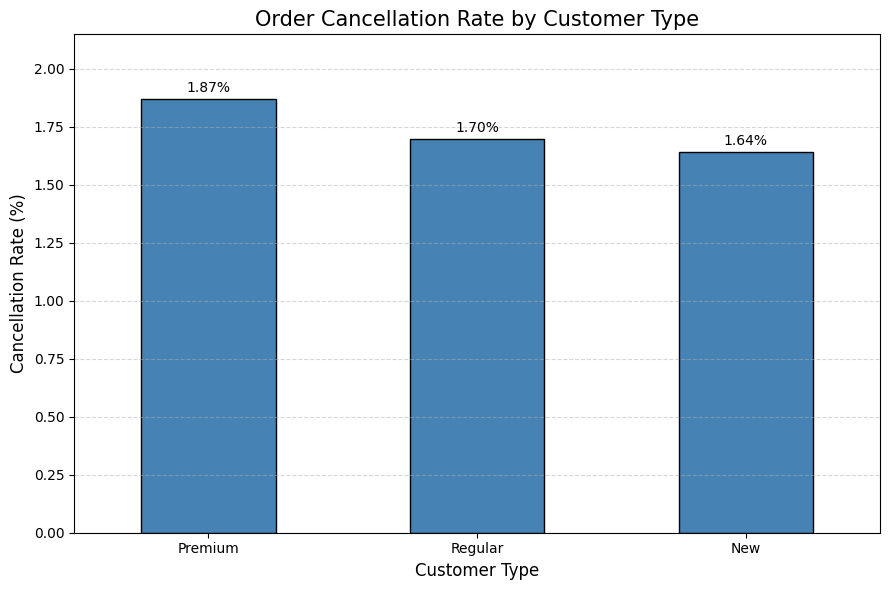

In [90]:
plt.figure(figsize=(9, 6))

ax = customer_cancellations['cancellation_rate'].plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Order Cancellation Rate by Customer Type', fontsize=15)
plt.xlabel('Customer Type', fontsize=12)
plt.ylabel('Cancellation Rate (%)', fontsize=12)
plt.xticks(rotation=0)

# Display percentage values
ax.bar_label(
    ax.containers[0],
    fmt='%.2f%%',
    padding=3
)

plt.ylim(
    0,
    customer_cancellations['cancellation_rate'].max() * 1.15
)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: Premium customers have the highest cancellation rate at 1.87%, followed by Regular customers (1.70%) and New customers (1.64%). The differences are small, suggesting that cancellation rates are relatively similar across customer types.

**Final Conclusion:**


The Exploratory Data Analysis of the Food Delivery Orders dataset, consisting of 50,000 records and 37 columns, revealed important insights into customer purchasing behaviour, revenue generation, restaurant performance, and delivery efficiency.

The analysis showed that Burger restaurants generate the highest revenue, Regular customers contribute the largest share of orders, and dinner is the highest-revenue meal period. Delivery time increases with traffic congestion, adverse weather, and delivery distance. Approximately 36.6% of deliveries are late, and late deliveries receive lower average customer ratings than on-time deliveries.

Most orders are successfully completed (98.26%), with driver unavailability being the most common cancellation reason. Fine Dining has the longest average preparation time, while customer ratings remain relatively consistent across restaurant categories.

Overall, the analysis identifies opportunities to improve delivery efficiency, reduce cancellations, and enhance customer satisfaction. These findings provide a foundation for better operational decisions and further analysis using statistical methods or predictive machine learning models.